# 3. Modèles supervisés, réglage d'alerte unique et choix du meilleur

| Modèle | Famille | Pourquoi lui |
| --- | --- | --- |
| Random Forest | arbres (bagging) | robuste, peu de réglages, explicable avec SHAP |
| Extra Trees | arbres (seuils tirés au hasard) | variance plus faible que le Random Forest sur des données bruitées |
| XGBoost | boosting de gradient | souvent le plus précis sur des données tabulaires |
| HistGradientBoosting | boosting par histogrammes (famille LightGBM, dans scikit-learn) | rapide, régularisé |
| Régression Logistique | linéaire | baseline interprétable : les arbres doivent faire mieux |
| MLP (64, 32) | réseau de neurones | une famille non-arbre au comparatif |

**Ce qui change par rapport à la version précédente (remarques du professeur)**

1. **Un seul réglage d'alerte** au lieu de deux seuils : un seuil de score **et** une règle de
   **persistance** (« alerte si au moins *k* des *n* dernières mesures dépassent le seuil »), choisis
   sur la **validation** pour avoir le **rappel le plus haut possible avec une précision ≥ 0,90 et au plus
   0,5 fausse alerte par heure**. L'opérateur ne peut pas traiter une fausse alerte toutes les 20 minutes.
2. Les modèles sont **classés sur la validation** : d'abord ceux qui tiennent la contrainte, puis le
   rappel, puis les fausses alertes, puis le délai (plus de F2, qui écrasait la précision).
3. **Zone de garde de 20 min** (≥ 15 min de fenêtre + 3 min de persistance) après les épisodes et en
   début de bloc changeant de rôle (notebook 2).
4. **Diagnostic train / validation / test** et **courbe d'apprentissage**.
5. Hyperparamètres réglés par une petite grille en **validation croisée groupée par bloc** sur le seul
   train (`backend/scripts/transmission_recherche.py`) ; nouvelles features (notebook 1).

Ce notebook travaille sur la **répétition 0** pour montrer chaque étape, puis lit les résultats
**cumulés sur 20 répétitions** produits par `backend/scripts/transmission_models.py`.

In [1]:
%%capture
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").is_dir())
sys.path[:0] = [str(ROOT / "backend"), str(ROOT / "backend" / "scripts")]
import build_dataset as bd
import transmission_real as tr
import transmission_models as tm
import transmission_study as ts
from app.domains.ml import pipeline
from app.core import paths

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (11, 3.5)
SEED = tr.SEED
COLS = {"weather": "temperature", "fridge": "fridge_temperature", "thermostat": "current_temperature"}
EPISODES_PATH = paths.PROCESSED_DIR / "episodes_transmission_reel.json"
MODEL_DIR = paths.MODELS_DIR / "transmission_reel"
import transmission_alertes as ta
import joblib
RES = json.load(open(MODEL_DIR / "comparaison_modeles.json", encoding="utf-8"))

In [2]:
df = pd.read_csv(tr.DATASET_PATH, parse_dates=["datetime"], keep_default_na=False)
df["garde"] = df["garde"].astype(str).str.lower().eq("true")
df, feats = tm.engineer(df)
episodes = json.load(open(EPISODES_PATH))
y = df["label"].to_numpy().astype(int)
split = tr.block_split(len(df), run=0)                       # 70/15/15 par blocs, recalculé
exclu = tr.excluded_rows(df["garde"].to_numpy(), run=0)       # zone de garde (20 min)
ev = {r: (split == r) & ~exclu for r in ("train", "val", "test")}
idx = {r: np.where(m)[0] for r, m in ev.items()}
X = df[feats].to_numpy(np.float32)
types = df["attack_type"].to_numpy()
print(f"{len(feats)} features ; " + " | ".join(f"{r} {len(i):,} lignes ({100 * y[i].mean():.1f} % d'attaques)" for r, i in idx.items()))
print(f"{int(exclu.sum()):,} lignes en zone de garde (ni apprises ni évaluées)")

53 features ; train 20,592 lignes (48.9 % d'attaques) | val 4,994 lignes (20.2 % d'attaques) | test 4,819 lignes (23.0 % d'attaques)
14,038 lignes en zone de garde (ni apprises ni évaluées)


## 3.1 Hyperparamètres : petite grille, validation croisée groupée par bloc

La recherche ne regarde que les lignes d'**entraînement** (4 plis `StratifiedGroupKFold`, groupe = bloc
d'une heure, score = précision moyenne AP). Le réglage retenu par modèle est relu automatiquement.

In [3]:
grille = json.load(open(MODEL_DIR / "recherche_hyperparametres.json", encoding="utf-8"))
pd.DataFrame([{"modèle": k, "réglage": json.dumps(e["params"]), "AP moyenne": e["ap_moyenne"], "écart-type": e["ap_ecart_type"],
               "retenu": "✔" if e["params"] == v["retenu"] else ""} for k, v in grille["modeles"].items() for e in v["essais"]])

,modèle,réglage,AP moyenne,écart-type,retenu
0,RandomForest,"{""min_samples_leaf"": 5, ""max_features"": ""sqrt""}",0.8945,0.0303,
1,RandomForest,"{""min_samples_leaf"": 10, ""max_features"": 0.3}",0.9007,0.0268,✔
2,RandomForest,"{""min_samples_leaf"": 2, ""max_features"": ""sqrt""}",0.8941,0.0313,
3,ExtraTrees,"{""min_samples_leaf"": 2, ""max_features"": ""sqrt""}",0.8947,0.0282,
4,ExtraTrees,"{""min_samples_leaf"": 5, ""max_features"": 0.5}",0.9049,0.0285,✔
5,XGBoost,"{""max_depth"": 4, ""min_child_weight"": 5}",0.8799,0.0439,✔
6,XGBoost,"{""max_depth"": 6, ""min_child_weight"": 1}",0.8774,0.0430,
7,XGBoost,"{""max_depth"": 8, ""min_child_weight"": 5}",0.8708,0.0419,
8,HistGB,"{""max_leaf_nodes"": 15, ""learning_rate"": 0.05}",0.8804,0.0389,
9,HistGB,"{""max_leaf_nodes"": 31, ""learning_rate"": 0.05}",0.8869,0.0375,


## 3.2 Validation croisée naïve contre groupée (démonstration de la fuite)

`StratifiedKFold` mélange les lignes : une même attaque, et les lignes voisines qui partagent ses fenêtres
glissantes, se retrouvent des deux côtés → score trop beau. `StratifiedGroupKFold` par bloc d'une heure
retire cette fuite. Résultat calculé par le script (répétition 0, seuil 0,5) :

In [4]:
cv = RES["validation_croisee"]
rows = []
for meth, m in cv["methodes"].items():
    for k, v in m["modeles"].items():
        rows.append({"méthode": meth, "blocs partagés": m["blocs_partages"], "modèle": k,
                     **{f"{x} (moy. ± é.-t.)": f"{v[x]['mean']:.3f} ± {v[x]['std']:.3f}" for x in ("average_precision", "recall", "precision")}})
pd.DataFrame(rows)

,méthode,blocs partagés,modèle,average_precision (moy. ± é.-t.),recall (moy. ± é.-t.),precision (moy. ± é.-t.)
0,naif,220,ExtraTrees,1.000 ± 0.000,0.996 ± 0.001,0.998 ± 0.000
1,naif,220,RandomForest,1.000 ± 0.000,0.989 ± 0.003,0.997 ± 0.001
2,naif,220,Logistique,0.897 ± 0.004,0.769 ± 0.015,0.830 ± 0.004
3,groupes_blocs,0,ExtraTrees,0.900 ± 0.034,0.712 ± 0.068,0.927 ± 0.048
4,groupes_blocs,0,RandomForest,0.899 ± 0.036,0.754 ± 0.070,0.887 ± 0.066
5,groupes_blocs,0,Logistique,0.844 ± 0.054,0.680 ± 0.098,0.772 ± 0.077


## 3.3 Entraînement des 6 modèles (répétition 0)

Pondération des classes (`class_weight`, `scale_pos_weight`, `sample_weight`), pas de SMOTE (des points
interpolés fabriqueraient des fenêtres glissantes qui n'existent pas). Logistique et MLP sont des pipelines
`StandardScaler → modèle`.

In [5]:
import time
scores, modeles = {}, {}
for key, nom in tm.MODELS:
    t0 = time.time()
    modeles[key], params = tm.fit_model(key, X, y, idx["train"])
    scores[key] = tm.scores_of(modeles[key], X)
    print(f"{nom:28s} {time.time() - t0:5.0f} s  {params}")

Random Forest                   81 s  {'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 0.3, 'max_leaf_nodes': None, 'min_samples_leaf': 10, 'n_estimators': 300}


Extra Trees                     36 s  {'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 0.5, 'max_leaf_nodes': None, 'min_samples_leaf': 5, 'n_estimators': 400}


XGBoost                          8 s  {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 400, 'subsample': 0.8, 'scale_pos_weight': 1.04}


HistGradientBoosting            70 s  {'class_weight': 'balanced', 'early_stopping': 'auto', 'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_depth': None, 'max_features': 1.0, 'max_iter': 300, 'max_leaf_nodes': 63, 'min_samples_leaf': 20}


Régression Logistique            6 s  {'class_weight': 'balanced', 'max_iter': 1000}


MLP — réseau de neurones        26 s  {'early_stopping': True, 'hidden_layer_sizes': (64, 32), 'learning_rate': 'constant', 'max_iter': 300, 'sample_weight': 'équilibré'}


## 3.4 Le réglage d'alerte unique, choisi sur la validation

Pour chaque modèle on essaie ~100 seuils × 7 règles de persistance (*k* sur *n* mesures, *n* ≤ 36 = 3 min)
sur la **validation**, et on garde la combinaison qui a le **rappel le plus haut** parmi celles qui ont une
**précision ≥ 0,90** et **≤ 0,5 fausse alerte par heure**. Une alerte = une suite continue de mesures en
alarme ; elle est fausse si elle ne recouvre aucune mesure falsifiée.

In [6]:
run0 = {"scores": scores, "y": y, "ev": ev, "episodes": episodes, "types": types}
ops, grilles = {}, {}
for key, nom in tm.MODELS:
    grilles[key] = ta.grid([{"s": scores[key], "y": y, "evaluated_val": ev["val"]}], "val")
    ops[key] = ta.choose(grilles[key])
pd.DataFrame({k: {"seuil": o["seuil"], "k/n": f"{o['k']}/{o['n']}", "précision val": o["precision"], "rappel val": o["recall"],
                  "FA/h val": o["fa_h"], "contrainte tenue": o["contrainte_tenue"]} for k, o in ops.items()}).T

,seuil,k/n,précision val,rappel val,FA/h val,contrainte tenue
RandomForest,0.89,12/24,0.9758,0.56,0.181,True
ExtraTrees,0.77,3/6,0.9403,0.5619,0.361,True
XGBoost,0.97,6/12,0.9306,0.4648,0.361,True
HistGB,0.995,12/24,0.9362,0.4945,0.361,True
Logistique,0.92,6/12,0.9114,0.3875,0.361,True
MLP,0.998,30/36,0.7626,0.449,0.361,False


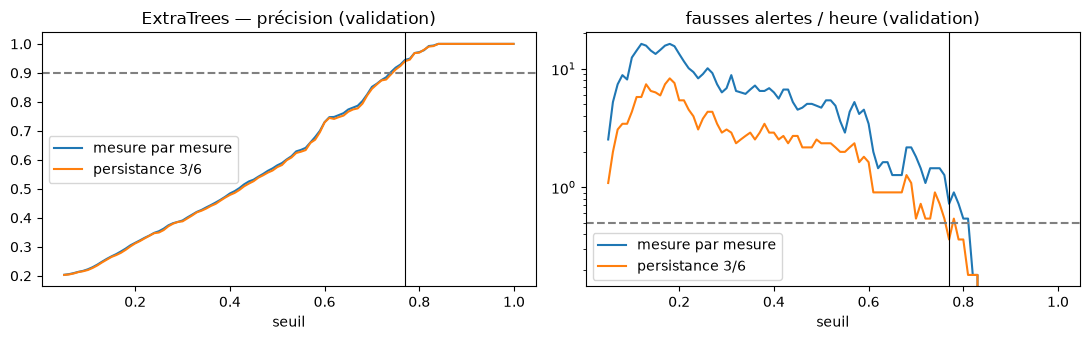

In [7]:
# Ce que la persistance change : précision et fausses alertes/h selon le seuil, sans (1/1) et avec la règle retenue
best0 = tm.rank_models({k: {"val_recall": ops[k]["recall"], "val_fausses_alarmes_par_heure": ops[k]["fa_h"],
                            "point_fonctionnement": ops[k]} for k in ops})[0]
g = pd.DataFrame(grilles[best0]); o = ops[best0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for (k, n), lab in (((1, 1), "mesure par mesure"), ((o["k"], o["n"]), f"persistance {o['k']}/{o['n']}")):
    s = g[(g.k == k) & (g.n == n)]
    axes[0].plot(s.seuil, s.precision, label=lab); axes[1].plot(s.seuil, s.fa_h, label=lab)
axes[0].axhline(ta.PRECISION_MIN, ls="--", c="gray"); axes[1].axhline(ta.FA_MAX, ls="--", c="gray")
axes[0].set_title(f"{best0} — précision (validation)"); axes[1].set_title("fausses alertes / heure (validation)")
axes[1].set_yscale("log")
for a in axes: a.set_xlabel("seuil"); a.axvline(o["seuil"], c="k", lw=0.8); a.legend()
plt.tight_layout()

## 3.5 Train, validation, test : sur- ou sous-apprentissage ? (répétition 0)

Chaque modèle est mesuré sur **ses propres données d'entraînement**, sur la validation et sur le test, au
même réglage d'alerte. AP = précision moyenne (aire sous la courbe précision-rappel, sans seuil).

In [8]:
lignes = []
for key, nom in tm.MODELS:
    m = tm.role_metrics([run0], key, ops[key])
    for r in ("train", "val", "test"):
        v = m["alarme"][r]
        lignes.append({"modèle": nom, "rôle": r, "AP": m["ap"][r], "rappel": v["recall"], "précision": v["precision"],
                       "F1": v["f1"], "FA/h": v["fausses_alarmes_evenements_par_heure"],
                       "épisodes": f"{v['episodes_detectes']}/{v['episodes']}", "délai (min)": v["delai_median_min"]})
pd.DataFrame(lignes).set_index(["modèle", "rôle"])

AP  rappel  précision      F1   FA/h  \
modèle                   rôle                                              
Random Forest            train  1.0000  0.8867     1.0000  0.9399  0.000   
                         val    0.8444  0.5600     0.9758  0.7116  0.181   
                         test   0.8905  0.4300     1.0000  0.6014  0.000   
Extra Trees              train  1.0000  0.9844     1.0000  0.9921  0.000   
                         val    0.8303  0.5619     0.9403  0.7035  0.361   
                         test   0.8704  0.6766     1.0000  0.8071  0.000   
XGBoost                  train  0.9999  0.7226     1.0000  0.8390  0.000   
                         val    0.7925  0.4648     0.9306  0.6200  0.361   
                         test   0.8543  0.5375     1.0000  0.6992  0.000   
HistGradientBoosting     train  1.0000  0.8438     1.0000  0.9153  0.000   
                         val    0.7633  0.4945     0.9362  0.6472  0.361   
                         test   0.8779  0.5131     1.0000  0.6782  0.000   
Régression Logistique    train  0.8983  0.3536     0.9928  0.5215  0.137   
                         val    0.7318  0.3875     0.9114  0.5438  0.361   
                         test   0.7707  0.4743     0.8692  0.6137  0.776   
MLP — réseau de neurones train  1.0000  0.6720     1.0000  0.8038  0.000   
                         val    0.6176  0.4490     0.7626  0.5652  0.361   
                         test   0.7385  0.5754     0.8493  0.6861  0.388   

                               épisodes  délai (min)  
modèle                   rôle                         
Random Forest            train    43/43          1.8  
                         val        4/4          6.0  
                         test       4/4         12.3  
Extra Trees              train    43/43          0.3  
                         val        4/4          8.4  
                         test       4/4          6.2  
XGBoost                  train    43/43          3.0  
                         val        4/4         10.3  
                         test       4/4          7.0  
HistGradientBoosting     train    43/43          2.2  
                         val        4/4         10.2  
                         test       4/4          7.5  
Régression Logistique    train    36/43          5.3  
                         val        3/4          3.6  
                         test       3/4          2.4  
MLP — réseau de neurones train    43/43          3.8  
                         val        3/4          3.2  
                         test       4/4          4.3

## 3.6 Résultats de référence : 20 répétitions cumulées

Les 20 rotations du cycle de blocs : chaque heure sert 3 fois de test. Le réglage d'alerte de chaque modèle
est choisi sur la validation **cumulée** des 20 répétitions (un seul réglage par modèle) ; le classement se
fait sur la validation ; le test ne fait que confirmer. `RF_v1` = Random Forest avec les **anciennes
features**, même protocole corrigé (ligne « avant / après »).

In [9]:
R = RES["resultats"]
lignes = []
for k in RES["classement_validation"] + ["RF_v1"]:
    r = R[k]; o = r["point_fonctionnement"]
    for role in ("train", "val", "test"):
        v = r["par_role"]["alarme"][role]
        lignes.append({"modèle": r["nom"], "réglage": f"≥ {o['seuil']:.3f}, {o['k']}/{o['n']}", "rôle": role,
                       "AP": r["par_role"]["ap"][role], "rappel": v["recall"], "précision": v["precision"], "F1": v["f1"],
                       "FA/h": v["fausses_alarmes_evenements_par_heure"], "épisodes": f"{v['episodes_detectes']}/{v['episodes']}",
                       "délai médian (min)": v["delai_median_min"]})
print("Classement sur la validation :", " > ".join(RES["classement_validation"]), "→ meilleur :", RES["meilleur_modele"])
pd.DataFrame(lignes).set_index(["modèle", "rôle"])

Classement sur la validation : ExtraTrees > RandomForest > XGBoost > HistGB > Logistique > MLP → meilleur : ExtraTrees


réglage      AP  \
modèle                                    rôle                            
Extra Trees                               train    ≥ 0.700, 3/6  1.0000   
                                          val      ≥ 0.700, 3/6  0.8178   
                                          test     ≥ 0.700, 3/6  0.8454   
Random Forest                             train   ≥ 0.790, 6/12  1.0000   
                                          val     ≥ 0.790, 6/12  0.8088   
                                          test    ≥ 0.790, 6/12  0.8325   
XGBoost                                   train  ≥ 0.840, 18/24  1.0000   
                                          val    ≥ 0.840, 18/24  0.7946   
                                          test   ≥ 0.840, 18/24  0.8377   
HistGradientBoosting                      train   ≥ 0.990, 6/12  1.0000   
                                          val     ≥ 0.990, 6/12  0.7849   
                                          test    ≥ 0.990, 6/12  0.8439   
Régression Logistique                     train    ≥ 0.985, 1/1  0.9114   
                                          val      ≥ 0.985, 1/1  0.6627   
                                          test     ≥ 0.985, 1/1  0.7087   
MLP — réseau de neurones                  train  ≥ 0.999, 30/36  1.0000   
                                          val    ≥ 0.999, 30/36  0.6301   
                                          test   ≥ 0.999, 30/36  0.6667   
Random Forest, anciennes features (avant) train  ≥ 0.710, 30/36  1.0000   
                                          val    ≥ 0.710, 30/36  0.7531   
                                          test   ≥ 0.710, 30/36  0.7643   

                                                 rappel  précision      F1  \
modèle                                    rôle                               
Extra Trees                               train  0.9869     1.0000  0.9934   
                                          val    0.6459     0.9240  0.7603   
                                          test   0.6518     0.9388  0.7694   
Random Forest                             train  0.9496     1.0000  0.9741   
                                          val    0.6079     0.9018  0.7262   
                                          test   0.6039     0.9213  0.7296   
XGBoost                                   train  0.8707     1.0000  0.9308   
                                          val    0.5896     0.9043  0.7138   
                                          test   0.6098     0.9158  0.7321   
HistGradientBoosting                      train  0.9403     1.0000  0.9692   
                                          val    0.5631     0.9091  0.6954   
                                          test   0.6151     0.9494  0.7465   
Régression Logistique                     train  0.2609     0.9939  0.4133   
                                          val    0.2548     0.9083  0.3979   
                                          test   0.2977     0.9328  0.4514   
MLP — réseau de neurones                  train  0.7136     1.0000  0.8329   
                                          val    0.4720     0.7478  0.5787   
                                          test   0.4840     0.8033  0.6040   
Random Forest, anciennes features (avant) train  0.8678     1.0000  0.9292   
                                          val    0.5219     0.9005  0.6608   
                                          test   0.5282     0.9347  0.6750   

                                                  FA/h épisodes  \
modèle                                    rôle                    
Extra Trees                               train  0.000  854/854   
                                          val    0.494    71/73   
                                          test   0.433    70/73   
Random Forest                             train  0.004  854/854   
                                          val    0.400    70/73   
                                          test   0.348    70/73   

In [10]:
b = R[RES["meilleur_modele"]]
pd.DataFrame({sc: {"épisodes détectés": f"{e['detected']}/{e['n']}", "délai médian (min)": e["delai_median_min"],
                   "mesures signalées (%)": b["per_attack"][sc]["rate"]} for sc, e in b["per_episode"].items()}).T

,épisodes détectés,délai médian (min),mesures signalées (%)
MITM_gel,8/8,1.0,95.0
MITM_rejeu,8/9,2.1,73.8
Injection_nominale,9/9,2.2,88.7
Injection_biais_0.5,9/10,11.0,26.9
Injection_biais_1.0,8/8,6.0,52.3
Injection_biais_2.0,7/7,3.0,83.9
Injection_derive,7/7,11.6,31.8
MITM_gel_thermostat,7/7,3.6,83.4
Injection_biais_thermostat,7/8,6.9,51.8


In [11]:
# Effet de la persistance sur le meilleur modèle (test cumulé) : même seuil, sans et avec la règle k/n
pd.DataFrame({niv: {x: b["par_role"][niv]["test"][x] for x in ("precision", "recall", "fausses_alarmes_evenements_par_heure",
                                                               "episodes_detectes", "delai_median_min")}
              for niv in ("ligne", "alarme")}).T

,precision,recall,fausses_alarmes_evenements_par_heure,episodes_detectes,delai_median_min
ligne,0.9411,0.6556,0.874,70.0,3.7
alarme,0.9388,0.6518,0.433,70.0,3.9


## 3.7 Courbe d'apprentissage du meilleur modèle

AP sur la part du train utilisée et sur la validation, selon la taille du train (blocs tirés au hasard),
moyenne de 3 rotations.

,part_train,lignes_train,ap_train,ap_val,f1_train,f1_val
0,0.10,1721,1.0,0.7227,0.9978,0.5793
1,0.25,4936,1.0,0.8035,0.9976,0.6351
2,0.50,10061,1.0,0.8563,0.9975,0.8039
3,0.75,15171,1.0,0.8699,0.9974,0.8079
4,1.00,20191,1.0,0.8808,0.9973,0.8188


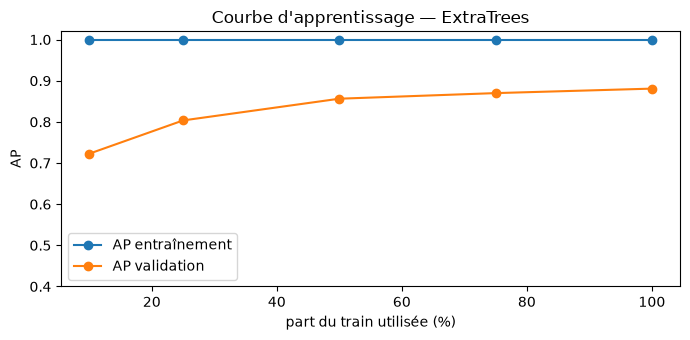

In [12]:
lc = pd.DataFrame(RES["courbe_apprentissage"]["points"])
plt.figure(figsize=(7, 3.5))
plt.plot(100 * lc.part_train, lc.ap_train, "o-", label="AP entraînement")
plt.plot(100 * lc.part_train, lc.ap_val, "o-", label="AP validation")
plt.xlabel("part du train utilisée (%)"); plt.ylabel("AP"); plt.ylim(0.4, 1.02); plt.legend()
plt.title(f"Courbe d'apprentissage — {RES['courbe_apprentissage']['modele']}"); plt.tight_layout()
lc

## 3.8 Conclusion (résultats cumulés sur 20 répétitions)

**Choix du modèle (validation).** L'**Extra Trees** tient la contrainte (précision ≥ 0,90, ≤ 0,5 fausse
alerte/h) avec le rappel de validation le plus haut (0,646) ; viennent ensuite Random Forest (0,608),
XGBoost (0,590) et HistGradientBoosting (0,563). La Régression Logistique tient la contrainte mais ne détecte
que 43 épisodes sur 73 ; le MLP ne la tient pas (précision de validation 0,75). Réglage retenu : score ≥ 0,70
et **3 mesures sur les 6 dernières** (30 s).

**Confirmation sur le test** (jamais utilisé pour choisir) : 70 épisodes détectés sur 73, **0,43 fausse
alerte par heure** (une toutes les 2 h 20 environ), précision 0,939, rappel 0,652, délai médian 3,9 min. Les
trois premiers modèles arborescents sont très proches sur le test : l'écart entre eux est de l'ordre de la
variabilité d'une répétition à l'autre ; l'Extra Trees est retenu parce qu'il est devant **sur la validation**.

**Avant / après.** Le Random Forest de la version précédente (anciennes features, même protocole corrigé et
même critère) ne détecte que 61 épisodes sur 73 au test (rappel 0,528, AP 0,764 contre 0,845) : le gain vient
surtout des nouvelles features (quantiles, min/max glissants). La règle de persistance divise les fausses
alertes par 2 pour l'Extra Trees (0,87 → 0,43 par heure au test) sans perdre d'épisode.

**Train / validation / test.** Tous les modèles arborescents sont quasi parfaits sur leur propre train
(AP 1,000, ROC-AUC 1,000) et nettement moins bons en validation (AP 0,82, ROC-AUC 0,89) : ils **sur-apprennent**
(ils mémorisent les lignes d'entraînement, normal pour des arbres profonds). Mais la validation et le test sont
au même niveau (AP 0,818 et 0,845) : le choix du seuil et du modèle sur la validation **généralise**. La courbe
d'apprentissage montre une AP de validation qui monte de 0,72 (10 % du train) à 0,88 (100 %) et continue de
monter lentement : le modèle est limité par la **quantité de données** (62 h de traces) et par le **bruit** du
capteur, pas par sa capacité ; ce n'est pas du sous-apprentissage. La Régression Logistique, elle, sous-apprend
(ROC-AUC 0,90 même sur son train). Attention : l'AP du train est calculée avec ~50 % d'attaques, celle de la
validation et du test avec ~17 % ; la ROC-AUC, qui ne dépend pas de cette proportion, confirme le diagnostic.